[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/09-rag/notebooks/02-embeddings-search-hybrid-rerank.ipynb)

# 09.02 — Embeddings, FAISS, BM25, hybrid search and reranking

**What you will learn**
- **Embeddings**: turning text into a **vector** (list of numbers) that captures meaning, and **cosine similarity** to compare them.
- **FAISS**: a library for fast vector search.
- **BM25**: classic keyword search, and where it beats embeddings.
- **Hybrid search** with **Reciprocal Rank Fusion (RRF)**: merging two ranked lists.
- **Reranking** with a **cross-encoder**: a slower, more careful second opinion.

Runs offline in about 2–3 minutes (downloads two small models, ~90 MB each).

## Find the data (works locally and in Colab)

The documents live in the module's `data/docs/` folder. Locally the notebook finds them next door. In Colab the cell downloads them (and the helper code) from the course's GitHub repository.

In [1]:
import sys, urllib.request
from pathlib import Path
RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/09-rag/"
DOC_NAMES = ['01-returns-policy.md', '02-exchanges.md', '03-shipping-and-delivery.md', '04-warranty.md', '05-repairs-service.md', '06-payments-and-billing.md', '07-price-match.md', '08-gold-membership.md', '09-gear-rental.md', '10-account-and-privacy.md', '11-sustainability.md', '12-stores-and-hours.md', '13-customer-support.md', '14-gift-cards.md', '15-safety-recalls.md']
EXTRA = ["data/eval_questions.json", "code/rag_pipeline.py"]

BASE = next((p for p in [Path(".."), Path("09-rag"), Path(".")] if (p / "data" / "docs").exists()), None)
if BASE is None:                                   # not found locally -> download (Colab)
    BASE = Path("09-rag")
    for rel in [f"data/docs/{n}" for n in DOC_NAMES] + EXTRA:
        dest = BASE / rel
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(RAW + rel, dest)
DOCS_DIR = BASE / "data" / "docs"
sys.path.insert(0, str(BASE / "code"))             # so "import rag_pipeline" works
print("documents folder:", DOCS_DIR.resolve(), "|", len(list(DOCS_DIR.glob("*.md"))), "files")

documents folder: /home/claude/AI-Engineer/09-rag/data/docs | 15 files


Load and chunk the documents with the heading strategy from notebook 01 (now imported from `rag_pipeline.py`).

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import rag_pipeline as rp
docs = rp.load_documents(DOCS_DIR)
chunks = rp.chunk_all(docs, "headings")
print(len(docs), "documents ->", len(chunks), "chunks")
print(chunks[10].chunk_id, "\n" + chunks[10].text)

15 documents -> 73 chunks
02-exchanges.md#4 
Exchanges > In-store exchanges
You can exchange online orders in any Brightleaf store. Bring the item and your order number. Store staff can check stock in all stores and ship the replacement to your home for free.


## 1. Embeddings: meaning as numbers

`all-MiniLM-L6-v2` turns any text into **384 numbers**. Texts with similar meaning get vectors pointing in similar directions. We **normalise** them (scale to length 1), so the **dot product** (multiply matching numbers, add them up) equals the **cosine similarity**: 1 = same meaning, about 0 = unrelated.

Let's embed five sentences and look at the similarity of every pair.

In [3]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
sentences = ["How long is the warranty on a tent?",
             "What guarantee do tents come with?",
             "Tents have a five-year warranty.",
             "When is the Hillcrest store open?",
             "Can I pay with PayPal?"]
vecs = embedder.encode(sentences, normalize_embeddings=True)
print("one vector has", vecs.shape[1], "numbers; first five:", np.round(vecs[0][:5], 3))
sim = vecs @ vecs.T                          # all pairwise dot products at once
pd.DataFrame(np.round(sim, 2), index=[s[:32] for s in sentences], columns=range(1, 6))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12908.25it/s]

one vector has 384 numbers; first five: [-0.033  0.117  0.075  0.037  0.052]


,1,2,3,4,5
How long is the warranty on a te,1.00,0.63,0.84,0.16,0.06
What guarantee do tents come wit,0.63,1.00,0.72,0.17,0.08
Tents have a five-year warranty.,0.84,0.72,1.00,0.12,0.05
When is the Hillcrest store open,0.16,0.17,0.12,1.00,-0.00
Can I pay with PayPal?,0.06,0.08,0.05,-0.00,1.00


Sentences 1–3 score high with each other even though sentence 2 shares almost no words with sentence 1 ("guarantee" vs "warranty"). The store-hours and payment sentences score low. A heatmap makes this easy to see.

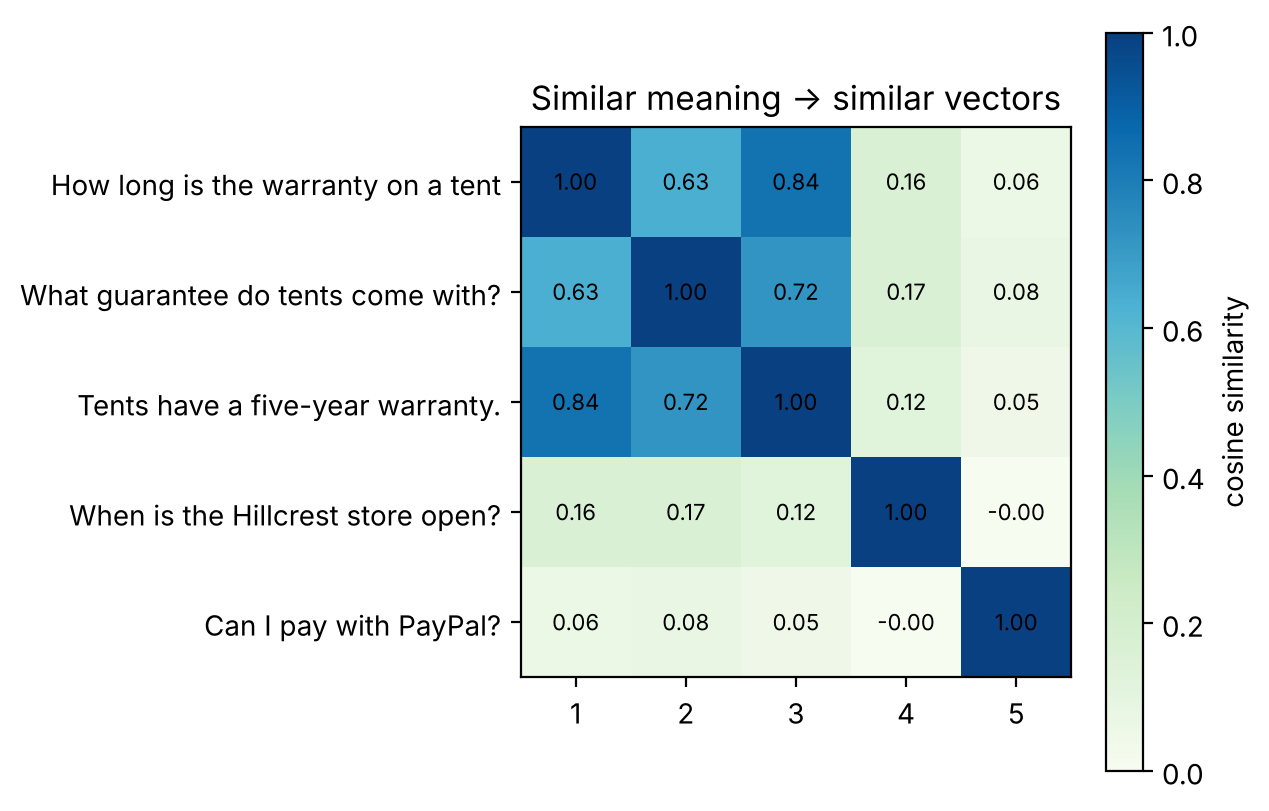

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(sim, cmap="GnBu", vmin=0, vmax=1)
ax.set_xticks(range(5), range(1, 6)); ax.set_yticks(range(5), [s[:34] for s in sentences])
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="cosine similarity"); ax.set_title("Similar meaning -> similar vectors")
plt.tight_layout(); plt.show()

## 2. A FAISS index over all chunks

**FAISS** stores vectors and finds the ones closest to a query vector. `IndexFlatIP` compares the query with every vector by inner (dot) product — exact, and plenty fast for thousands of chunks. (For millions you would use an approximate index such as HNSW.) FAISS stores only vectors, so we keep the chunk list alongside to map result positions back to text.

In [5]:
import faiss
chunk_vecs = embedder.encode([c.text for c in chunks], normalize_embeddings=True).astype("float32")
index = faiss.IndexFlatIP(chunk_vecs.shape[1])
index.add(chunk_vecs)
print("vectors in index:", index.ntotal)

def dense_search(query, k=5):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    return [(chunks[i], float(s)) for i, s in zip(ids[0], scores[0])]

for c, s in dense_search("What guarantee do tents come with?", 3):
    print(f"{s:.3f}  {c.chunk_id:<28} {c.section}")

vectors in index: 73
0.487  04-warranty.md#1             Warranty periods
0.451  05-repairs-service.md#2      Prices
0.424  09-gear-rental.md#1          What you can rent


The warranty chunk comes first even though the question says "guarantee". That is the power of embeddings.

## 3. BM25 keyword search

**BM25** scores chunks by shared words, giving more weight to **rare** words and less to common ones. First we **tokenize** (split text into lowercase words and drop very common "stop words" like *the*, *is*).

In [6]:
from rank_bm25 import BM25Okapi
print(rp.tokenize("My headlamp serial starts with TG3-26A, what should I do?"))
bm25 = BM25Okapi([rp.tokenize(c.text) for c in chunks])

def bm25_search(query, k=5):
    scores = bm25.get_scores(rp.tokenize(query))
    top = np.argsort(-scores)[:k]
    return [(chunks[i], float(scores[i])) for i in top]

for c, s in bm25_search("What guarantee do tents come with?", 3):
    print(f"{s:6.2f}  {c.chunk_id:<28} {c.section}")

['headlamp', 'serial', 'starts', 'tg3-26a', 'should']
  3.70  09-gear-rental.md#1          What you can rent
  2.54  04-warranty.md#1             Warranty periods
  0.00  01-returns-policy.md#2       Condition of returned items


## 4. Where each one wins

Let's compare the top result of each method on three kinds of question:
- a **paraphrase** (different words, same meaning) — embeddings should win;
- an **exact code** (`TG3-26A`) — BM25 should be strong;
- a question that shares a **misleading keyword** with the wrong document.

In [7]:
queries = ["What guarantee do tents come with?",
           "My headlamp serial starts with TG3-26A, what should I do?",
           "How long until my money comes back after I send something back?"]
rows = []
for q in queries:
    d = dense_search(q, 3); b = bm25_search(q, 3)
    rows.append({"question": q[:45], "dense top-3": [c.doc_id[:14] for c, _ in d],
                 "bm25 top-3": [c.doc_id[:14] for c, _ in b]})
pd.DataFrame(rows)

,question,dense top-3,bm25 top-3
0,What guarantee do tents come with?,"[04-warranty.md, 05-repairs-ser, 09-gear-rental]","[09-gear-rental, 04-warranty.md, 01-returns-pol]"
1,"My headlamp serial starts with TG3-26A, what","[15-safety-reca, 05-repairs-ser, 15-safety-reca]","[15-safety-reca, 01-returns-pol, 01-returns-pol]"
2,How long until my money comes back after I se,"[01-returns-pol, 06-payments-an, 02-exchanges.m]","[09-gear-rental, 02-exchanges.m, 01-returns-pol]"


Read the table: which method found the right document first for each question? On real corpora each method has blind spots — which is why we combine them.

## 5. Hybrid search with Reciprocal Rank Fusion (RRF)

BM25 scores (like 7.3) and cosine scores (like 0.62) are on different scales, so we cannot add them. **RRF** uses only **ranks**: each chunk gets `1 / (k + rank)` from each list, and we add them up. `k = 60` is the standard value.

First a tiny worked example with letters instead of chunks.

In [8]:
def rrf(rankings, k=60):
    scores = {}
    for ranking in rankings:
        for rank, item in enumerate(ranking, start=1):
            scores[item] = scores.get(item, 0) + 1 / (k + rank)
    return sorted(scores.items(), key=lambda x: -x[1])

dense_list = ["A", "B", "C", "D"]
bm25_list = ["C", "A", "E", "B"]
for item, score in rrf([dense_list, bm25_list]):
    print(item, round(score, 4))

A 0.0325
C 0.0323
B 0.0318
E 0.0159
D 0.0156


A (ranked 1st and 2nd) wins; C (3rd and 1st) is close behind; E and D, found by only one method, come last. Now on real chunks:

In [9]:
def hybrid_search(query, k=5, candidates=20):
    d = [c.chunk_id for c, _ in dense_search(query, candidates)]
    b = [c.chunk_id for c, _ in bm25_search(query, candidates)]
    by_id = {c.chunk_id: c for c in chunks}
    return [(by_id[cid], s) for cid, s in rrf([d, b])[:k]]

for q in queries:
    print("Q:", q)
    for c, s in hybrid_search(q, 3):
        print(f"   {s:.4f}  {c.chunk_id:<28} {c.section}")

Q: What guarantee do tents come with?
   0.0325  04-warranty.md#1             Warranty periods
   0.0323  09-gear-rental.md#1          What you can rent
   0.0308  01-returns-policy.md#2       Condition of returned items
Q: My headlamp serial starts with TG3-26A, what should I do?
   0.0328  15-safety-recalls.md#1       Current recall: TrailGlow 300 headlamp
   0.0300  01-returns-policy.md#2       Condition of returned items
   0.0260  04-warranty.md#1             Warranty periods
Q: How long until my money comes back after I send something back?
   0.0323  01-returns-policy.md#5       Refund timing
   0.0320  02-exchanges.md#2            Stock availability
   0.0312  03-shipping-and-delivery.md#3 Missing or late parcels


## 6. Reranking with a cross-encoder

The embedding model compares two *separate* vectors (a **bi-encoder**). A **cross-encoder** reads the question and a chunk *together* and outputs one relevance score — more accurate, but slower, so we only use it on the top ~20 candidates. Analogy: HR skims 500 CVs, the manager interviews 20.

In [10]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def rerank(query, candidates, k=5):
    scores = reranker.predict([(query, c.text) for c in candidates])
    order = np.argsort(-scores)[:k]
    return [(candidates[i], float(scores[i])) for i in order]

q = "How long until my money comes back after I send something back?"
cands = [c for c, _ in hybrid_search(q, k=20)]
print("BEFORE reranking (hybrid order):")
for c in cands[:5]:
    print("   ", c.chunk_id, "|", c.section)
print("AFTER reranking (cross-encoder):")
for c, s in rerank(q, cands, 5):
    print(f"   {s:6.2f}", c.chunk_id, "|", c.section)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 3146.51it/s]

BEFORE reranking (hybrid order):
    01-returns-policy.md#5 | Refund timing
    02-exchanges.md#2 | Stock availability
    03-shipping-and-delivery.md#3 | Missing or late parcels
    06-payments-and-billing.md#2 | Failed payments
    07-price-match.md#2 | Time limit
AFTER reranking (cross-encoder):


     0.48 01-returns-policy.md#5 | Refund timing
    -0.14 01-returns-policy.md#1 | Return window
    -1.04 03-shipping-and-delivery.md#3 | Missing or late parcels
    -1.49 02-exchanges.md#2 | Stock availability
    -1.69 06-payments-and-billing.md#2 | Failed payments


Cross-encoder scores are not probabilities (they can be negative); only their **order** matters. The chunk that actually answers the question ("Refund timing") should now be at or near the top.

## 7. Timing: why two stages?

Embedding search over all chunks is very fast; the cross-encoder is slower per chunk. Measure both.

In [11]:
import time
t = time.time(); [dense_search(q, 20) for _ in range(20)]; dense_ms = (time.time() - t) / 20 * 1000
t = time.time(); rerank(q, cands, 5); rerank_ms = (time.time() - t) * 1000
print(f"dense search over {len(chunks)} chunks: {dense_ms:.1f} ms per query")
print(f"cross-encoder on 20 candidates:      {rerank_ms:.1f} ms per query")
print("Running the cross-encoder on EVERY chunk of a million-chunk index would be far too slow - hence two stages.")

dense search over 73 chunks: 10.4 ms per query
cross-encoder on 20 candidates:      268.6 ms per query
Running the cross-encoder on EVERY chunk of a million-chunk index would be far too slow - hence two stages.


## Recap
- **Embeddings** capture meaning; compare with **cosine similarity** (dot product of normalised vectors).
- **FAISS** finds nearest vectors fast; it stores only vectors, you keep the text.
- **BM25** matches words and loves rare terms like product codes; it misses synonyms.
- **RRF** merges ranked lists using ranks only.
- A **cross-encoder** reranks the top candidates more accurately.

**Try it:** write two questions of your own — one that should favour BM25, one that should favour embeddings — and check with the table in section 4.